# Cryptocurrency Price Forecasting
## Exploratory Data Analysis (EDA)

### Algorithms
- LSTM
- LightGBM

### Objective
To analyze historical Bitcoin OHLCV data and understand
its structure, quality, trends, volume behavior and potential
outliers before applying machine learning models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Project paths

DATA_PATH = Path("../data/raw/bitcoin_daily.csv")
GRAPH_PATH = Path("../outputs/graphs")

# Create graph folder if it doesn't exist
GRAPH_PATH.mkdir(parents=True, exist_ok=True)

print("Dataset path:")
print(DATA_PATH.resolve())

print("\nGraph output path:")
print(GRAPH_PATH.resolve())

Dataset path:
C:\Crypto_Forecasting_Project\LSTM_Light_BGM\data\raw\bitcoin_daily.csv

Graph output path:
C:\Crypto_Forecasting_Project\LSTM_Light_BGM\outputs\graphs


In [3]:
# Check whether the dataset exists

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATA_PATH.resolve()}\n\n"
        "Make sure bitcoin_daily.csv is inside data/raw/"
    )

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (72946, 10)


In [4]:
df.head()

,Unnamed: 0,open,high,low,close,volume,marketCap,timestamp,crypto_name,date
0,0,112.900002,118.800003,107.142998,115.910004,0.0,1.288693e+09,2013-05-05T23:59:59.999Z,Bitcoin,2013-05-05
1,1,3.493130,3.692460,3.346060,3.590890,0.0,6.229819e+07,2013-05-05T23:59:59.999Z,Litecoin,2013-05-05
2,2,115.980003,124.663002,106.639999,112.300003,0.0,1.249023e+09,2013-05-06T23:59:59.999Z,Bitcoin,2013-05-06
3,3,3.594220,3.781020,3.116020,3.371250,0.0,5.859436e+07,2013-05-06T23:59:59.999Z,Litecoin,2013-05-06
4,4,112.250000,113.444000,97.699997,111.500000,0.0,1.240594e+09,2013-05-07T23:59:59.999Z,Bitcoin,2013-05-07


In [5]:
df.tail()

,Unnamed: 0,open,high,low,close,volume,marketCap,timestamp,crypto_name,date
72941,72941,0.022604,0.022988,0.022197,0.022796,4.040134e+07,1.652957e+09,2022-10-23T23:59:59.999Z,VeChain,2022-10-23
72942,72942,1.468244,1.530464,1.435415,1.517878,2.844351e+07,1.572825e+09,2022-10-23T23:59:59.999Z,Flow,2022-10-23
72943,72943,4.950431,5.148565,4.945280,5.117206,1.069497e+08,1.559551e+09,2022-10-23T23:59:59.999Z,Filecoin,2022-10-23
72944,72944,0.000233,0.000243,0.000226,0.000239,2.143268e+08,1.576291e+09,2022-10-23T23:59:59.999Z,Terra Classic,2022-10-23
72945,72945,0.465490,0.471006,0.453438,0.469033,9.509743e+08,2.339868e+10,2022-10-23T23:59:59.999Z,XRP,2022-10-23


In [6]:
rows, columns = df.shape

print("Number of rows    :", rows)
print("Number of columns :", columns)

Number of rows    : 72946
Number of columns : 10


In [7]:
if rows >= 500:
    print("\n✓ Dataset satisfies the minimum 500-sample requirement.")
else:
    print("\n✗ Dataset has fewer than 500 samples.")


✓ Dataset satisfies the minimum 500-sample requirement.


In [8]:
print("Dataset columns:\n")

for column in df.columns:
    print(column)

Dataset columns:

Unnamed: 0
open
high
low
close
volume
marketCap
timestamp
crypto_name
date


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72946 entries, 0 to 72945
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   72946 non-null  int64  
 1   open         72946 non-null  float64
 2   high         72946 non-null  float64
 3   low          72946 non-null  float64
 4   close        72946 non-null  float64
 5   volume       72946 non-null  float64
 6   marketCap    72946 non-null  float64
 7   timestamp    72946 non-null  str    
 8   crypto_name  72946 non-null  str    
 9   date         72946 non-null  str    
dtypes: float64(6), int64(1), str(3)
memory usage: 8.5 MB


In [10]:
df.describe()

,Unnamed: 0,open,high,low,close,volume,marketCap
count,72946.000000,72946.000000,7.294600e+04,72946.000000,7.294600e+04,7.294600e+04,7.294600e+04
mean,36472.500000,870.194495,8.964124e+02,844.060640,8.712949e+02,2.207607e+09,1.474922e+10
std,21057.840705,5231.654470,5.398613e+03,5079.389387,5.235508e+03,9.617885e+09,7.501159e+10
min,0.000000,0.000000,1.022100e-10,0.000000,8.292000e-11,0.000000e+00,0.000000e+00
25%,18236.250000,0.167916,1.767999e-01,0.158630,1.682982e-01,8.320618e+06,1.860432e+08
50%,36472.500000,1.630666,1.717542e+00,1.541486,1.640219e+00,1.098756e+08,1.268539e+09
75%,54708.750000,26.070557,2.756868e+01,24.791776,2.625195e+01,6.691398e+08,5.118618e+09
max,72945.000000,67549.735581,1.621883e+05,66458.723733,6.756683e+04,3.509679e+11,1.274831e+12


In [11]:
missing_values = df.isnull().sum()

print("Missing values in each column:\n")
print(missing_values)

Missing values in each column:

Unnamed: 0     0
open           0
high           0
low            0
close          0
volume         0
marketCap      0
timestamp      0
crypto_name    0
date           0
dtype: int64


In [12]:
missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

display(missing_table)

,Missing Values,Missing Percentage
Unnamed: 0,0,0.0
open,0,0.0
high,0,0.0
low,0,0.0
close,0,0.0
volume,0,0.0
marketCap,0,0.0
timestamp,0,0.0
crypto_name,0,0.0
date,0,0.0


In [13]:
duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


In [14]:
if "Date" in df.columns:

    duplicate_dates = df["Date"].duplicated().sum()

    print(
        "Number of duplicate dates:",
        duplicate_dates
    )

else:

    print("Date column not found.")

Date column not found.


In [15]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print(df["date"].dtype)

datetime64[us]


In [16]:
invalid_dates = df["date"].isnull().sum()

print(
    "Invalid/missing dates:",
    invalid_dates
)

Invalid/missing dates: 0


In [17]:
print("Starting date:", df["date"].min())
print("Ending date  :", df["date"].max())

print(
    "\nTotal time span:",
    df["date"].max() - df["date"].min()
)


Starting date: 2013-05-05 00:00:00
Ending date  : 2022-10-23 00:00:00

Total time span: 3458 days 00:00:00


In [18]:
print(
    "Dates sorted:",
    df["date"].is_monotonic_increasing
)

Dates sorted: True


In [19]:
print(df.dtypes)

Unnamed: 0              int64
open                  float64
high                  float64
low                   float64
close                 float64
volume                float64
marketCap             float64
timestamp                 str
crypto_name               str
date           datetime64[us]
dtype: object


In [20]:
# Rename the columns we need for the project

df = df.rename(columns={
    "date": "Date",
    "open": "Open",
    "high": "High",
    "low": "Low",
    "close": "Close",
    "volume": "Volume"
})

print("Columns after renaming:")
print(df.columns.tolist())

Columns after renaming:
['Unnamed: 0', 'Open', 'High', 'Low', 'Close', 'Volume', 'marketCap', 'timestamp', 'crypto_name', 'Date']


In [21]:
# Keep only the columns required for Bitcoin OHLCV forecasting

required_columns = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

df = df[required_columns].copy()

print("Selected columns:")
print(df.columns.tolist())

display(df.head())

Selected columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume']


,Date,Open,High,Low,Close,Volume
0,2013-05-05,112.900002,118.800003,107.142998,115.910004,0.0
1,2013-05-05,3.493130,3.692460,3.346060,3.590890,0.0
2,2013-05-06,115.980003,124.663002,106.639999,112.300003,0.0
3,2013-05-06,3.594220,3.781020,3.116020,3.371250,0.0
4,2013-05-07,112.250000,113.444000,97.699997,111.500000,0.0


In [22]:
print("Data types:\n")

print(df.dtypes)

Data types:

Date      datetime64[us]
Open             float64
High             float64
Low              float64
Close            float64
Volume           float64
dtype: object


In [23]:
numeric_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print("Data types after conversion:\n")
print(df.dtypes)

Data types after conversion:

Date      datetime64[us]
Open             float64
High             float64
Low              float64
Close            float64
Volume           float64
dtype: object


In [24]:
print("Missing values:\n")

display(
    df.isnull().sum()
)

Missing values:



Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

In [25]:
invalid_dates = df["Date"].isnull().sum()

print(
    "Invalid/missing dates:",
    invalid_dates
)

Invalid/missing dates: 0


In [26]:
# Sort data from oldest to newest

df = df.sort_values(
    "Date"
).reset_index(drop=True)

print(
    "Dates sorted:",
    df["Date"].is_monotonic_increasing
)

Dates sorted: True


In [27]:
duplicate_rows = df.duplicated().sum()

print(
    "Duplicate rows:",
    duplicate_rows
)

Duplicate rows: 0


In [28]:
duplicate_dates = df["Date"].duplicated().sum()

print(
    "Duplicate dates:",
    duplicate_dates
)

Duplicate dates: 69698


In [29]:
# Reload the ORIGINAL dataset
raw_df = pd.read_csv(DATA_PATH)

print("Original columns:")
print(raw_df.columns.tolist())

print("\nDataset shape:")
print(raw_df.shape)

Original columns:
['Unnamed: 0', 'open', 'high', 'low', 'close', 'volume', 'marketCap', 'timestamp', 'crypto_name', 'date']

Dataset shape:
(72946, 10)


In [30]:
print("Number of unique cryptocurrencies:")

print(
    raw_df["crypto_name"].nunique()
)

print("\nCryptocurrencies:")

print(
    raw_df["crypto_name"].unique()[:30]
)

Number of unique cryptocurrencies:
56

Cryptocurrencies:
<ArrowStringArray>
[              'Bitcoin',              'Litecoin',                   'XRP',
              'Dogecoin',                'Monero',               'Stellar',
                'Tether',              'Ethereum',      'Ethereum Classic',
                 'Maker', 'Basic Attention Token',                   'EOS',
          'Bitcoin Cash',                   'BNB',                  'TRON',
          'Decentraland',             'Chainlink',               'Cardano',
              'Filecoin',         'Theta Network',           'Huobi Token',
             'Ravencoin',                 'Tezos',               'VeChain',
                 'Quant',              'USD Coin',                'Cronos',
       'Wrapped Bitcoin',                'Cosmos',               'Polygon']
Length: 30, dtype: str


In [31]:
print(
    raw_df["crypto_name"]
    .value_counts()
    .head(20)
)

crypto_name
Bitcoin                  3248
Litecoin                 3248
XRP                      3157
Dogecoin                 3024
Monero                   2866
Stellar                  2791
Tether                   2582
Ethereum                 2424
Ethereum Classic         2072
Basic Attention Token    1760
EOS                      1730
Bitcoin Cash             1708
BNB                      1706
TRON                     1656
Decentraland             1652
Chainlink                1649
Cardano                  1638
Maker                    1605
Filecoin                 1565
Theta Network            1530
Name: count, dtype: int64


In [32]:
display(
    raw_df[
        [
            "date",
            "crypto_name",
            "open",
            "high",
            "low",
            "close",
            "volume"
        ]
    ].head(20)
)

,date,crypto_name,open,high,low,close,volume
0,2013-05-05,Bitcoin,112.900002,118.800003,107.142998,115.910004,0.0
1,2013-05-05,Litecoin,3.493130,3.692460,3.346060,3.590890,0.0
2,2013-05-06,Bitcoin,115.980003,124.663002,106.639999,112.300003,0.0
3,2013-05-06,Litecoin,3.594220,3.781020,3.116020,3.371250,0.0
4,2013-05-07,Bitcoin,112.250000,113.444000,97.699997,111.500000,0.0
5,2013-05-07,Litecoin,3.370870,3.406720,2.939790,3.332740,0.0
6,2013-05-08,Litecoin,3.283620,3.491120,3.283620,3.409240,0.0
7,2013-05-08,Bitcoin,109.599998,115.779999,109.599998,113.566002,0.0
8,2013-05-09,Litecoin,3.399400,3.441690,3.294850,3.416150,0.0
9,2013-05-09,Bitcoin,113.199997,113.459999,109.260002,112.669998,0.0


In [33]:
# Reload the original dataset because crypto_name
# was removed from the earlier dataframe

df = pd.read_csv(DATA_PATH)

print("Original shape:", df.shape)
print("Original columns:")
print(df.columns.tolist())

Original shape: (72946, 10)
Original columns:
['Unnamed: 0', 'open', 'high', 'low', 'close', 'volume', 'marketCap', 'timestamp', 'crypto_name', 'date']


In [34]:
# Keep only Bitcoin records

df = df[
    df["crypto_name"] == "Bitcoin"
].copy()

print(
    "Bitcoin dataset shape:",
    df.shape
)

display(df.head())

Bitcoin dataset shape: (3248, 10)


,Unnamed: 0,open,high,low,close,volume,marketCap,timestamp,crypto_name,date
0,0,112.900002,118.800003,107.142998,115.910004,0.0,1.288693e+09,2013-05-05T23:59:59.999Z,Bitcoin,2013-05-05
2,2,115.980003,124.663002,106.639999,112.300003,0.0,1.249023e+09,2013-05-06T23:59:59.999Z,Bitcoin,2013-05-06
4,4,112.250000,113.444000,97.699997,111.500000,0.0,1.240594e+09,2013-05-07T23:59:59.999Z,Bitcoin,2013-05-07
7,7,109.599998,115.779999,109.599998,113.566002,0.0,1.264049e+09,2013-05-08T23:59:59.999Z,Bitcoin,2013-05-08
9,9,113.199997,113.459999,109.260002,112.669998,0.0,1.254535e+09,2013-05-09T23:59:59.999Z,Bitcoin,2013-05-09


In [35]:
# Rename columns to standard names

df = df.rename(columns={
    "date": "Date",
    "open": "Open",
    "high": "High",
    "low": "Low",
    "close": "Close",
    "volume": "Volume"
})

# Keep only required columns
df = df[
    [
        "Date",
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ]
].copy()

print("Columns:")
print(df.columns.tolist())

display(df.head())

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume']


,Date,Open,High,Low,Close,Volume
0,2013-05-05,112.900002,118.800003,107.142998,115.910004,0.0
2,2013-05-06,115.980003,124.663002,106.639999,112.300003,0.0
4,2013-05-07,112.250000,113.444000,97.699997,111.500000,0.0
7,2013-05-08,109.599998,115.779999,109.599998,113.566002,0.0
9,2013-05-09,113.199997,113.459999,109.260002,112.669998,0.0


In [36]:
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

print(
    "Date datatype:",
    df["Date"].dtype
)

Date datatype: datetime64[us]


In [37]:
numeric_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print(df.dtypes)

Date      datetime64[us]
Open             float64
High             float64
Low              float64
Close            float64
Volume           float64
dtype: object


In [38]:
print("Missing values:")

display(
    df.isnull().sum()
)

Missing values:


Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

In [39]:
df = df.sort_values(
    "Date"
).reset_index(drop=True)

print(
    "Dates sorted:",
    df["Date"].is_monotonic_increasing
)

Dates sorted: True


In [40]:
duplicate_dates = df[
    "Date"
].duplicated().sum()

print(
    "Duplicate Bitcoin dates:",
    duplicate_dates
)

Duplicate Bitcoin dates: 0


In [41]:
print("Missing values before handling:")

display(
    df[numeric_columns].isnull().sum()
)

# Forward fill
df[numeric_columns] = (
    df[numeric_columns]
    .ffill()
)

# Remove remaining missing rows
df = df.dropna(
    subset=numeric_columns
).reset_index(drop=True)

print("\nMissing values after handling:")

display(
    df[numeric_columns].isnull().sum()
)

Missing values before handling:


Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


Missing values after handling:


Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

In [42]:
print(
    "Number of Bitcoin samples:",
    len(df)
)

if len(df) >= 500:

    print(
        "✓ Dataset satisfies the minimum 500-sample requirement."
    )

else:

    print(
        "✗ Dataset has fewer than 500 samples."
    )

Number of Bitcoin samples: 3248
✓ Dataset satisfies the minimum 500-sample requirement.


In [43]:
print(
    "Starting date:",
    df["Date"].min()
)

print(
    "Ending date:",
    df["Date"].max()
)

print(
    "\nTotal time span:",
    df["Date"].max()
    -
    df["Date"].min()
)

Starting date: 2013-05-05 00:00:00
Ending date: 2022-10-23 00:00:00

Total time span: 3458 days 00:00:00


In [44]:
print("Dataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape:
(3248, 6)

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume']

Data types:
Date      datetime64[us]
Open             float64
High             float64
Low              float64
Close            float64
Volume           float64
dtype: object

First 5 rows:


,Date,Open,High,Low,Close,Volume
0,2013-05-05,112.900002,118.800003,107.142998,115.910004,0.0
1,2013-05-06,115.980003,124.663002,106.639999,112.300003,0.0
2,2013-05-07,112.250000,113.444000,97.699997,111.500000,0.0
3,2013-05-08,109.599998,115.779999,109.599998,113.566002,0.0
4,2013-05-09,113.199997,113.459999,109.260002,112.669998,0.0


In [45]:
display(
    df[
        [
            "Open",
            "High",
            "Low",
            "Close",
            "Volume"
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Open,3248.0,9.682455e+03,1.505321e+04,68.504997,4.500593e+02,3.756953e+03,9.700149e+03,6.754974e+04
High,3248.0,9.937632e+03,1.544720e+04,74.561096,4.566265e+02,3.875225e+03,9.910138e+03,6.878963e+04
Low,3248.0,9.403189e+03,1.460389e+04,65.526001,4.438722e+02,3.656493e+03,9.512194e+03,6.638206e+04
Close,3248.0,9.694587e+03,1.506180e+04,68.431000,4.501113e+02,3.770344e+03,9.707214e+03,6.756683e+04
Volume,3248.0,1.243484e+10,1.887612e+10,0.000000,3.791335e+07,2.484940e+09,2.135713e+10,3.509679e+11


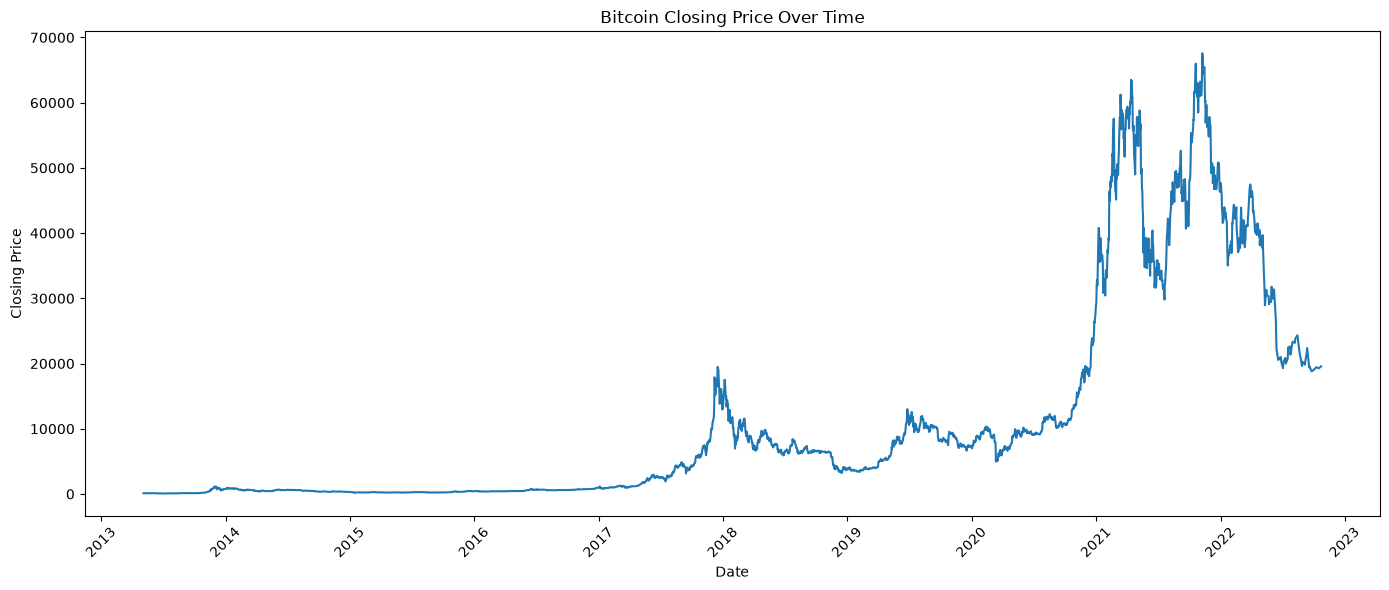

In [46]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Close"]
)

plt.title(
    "Bitcoin Closing Price Over Time"
)

plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    GRAPH_PATH / "01_bitcoin_price_history.png",
    dpi=200
)

plt.show()

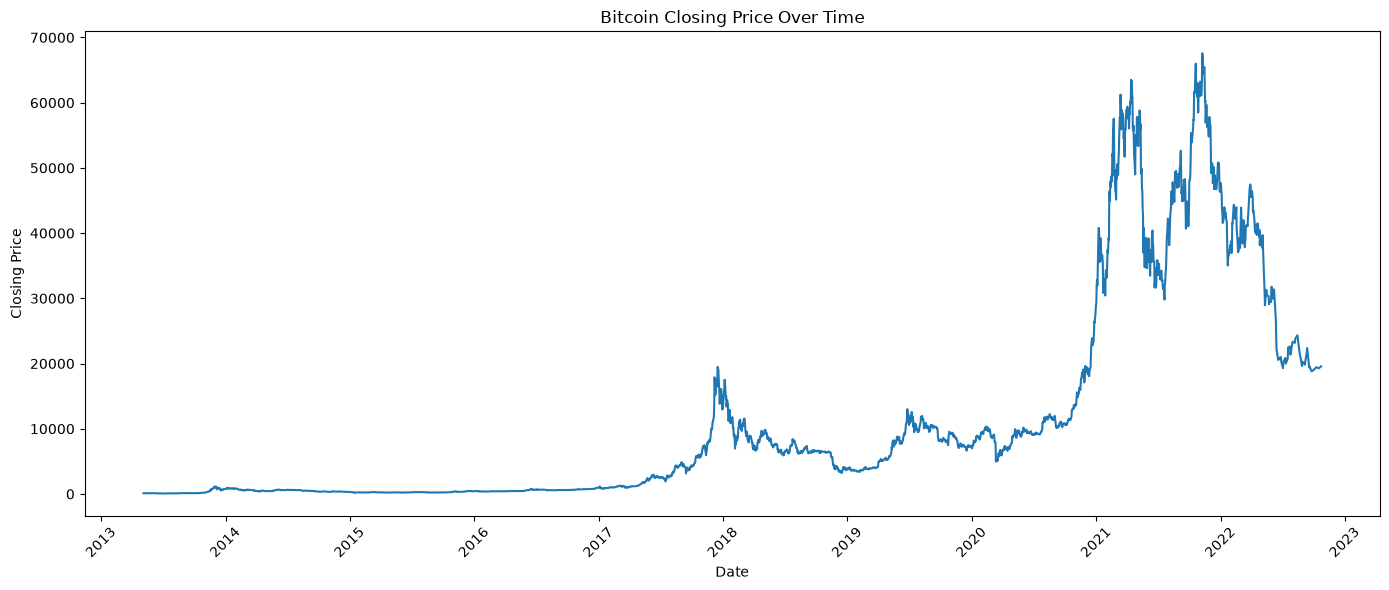

In [47]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Close"]
)

plt.title(
    "Bitcoin Closing Price Over Time"
)

plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    GRAPH_PATH / "01_bitcoin_price_history.png",
    dpi=200
)

plt.show()

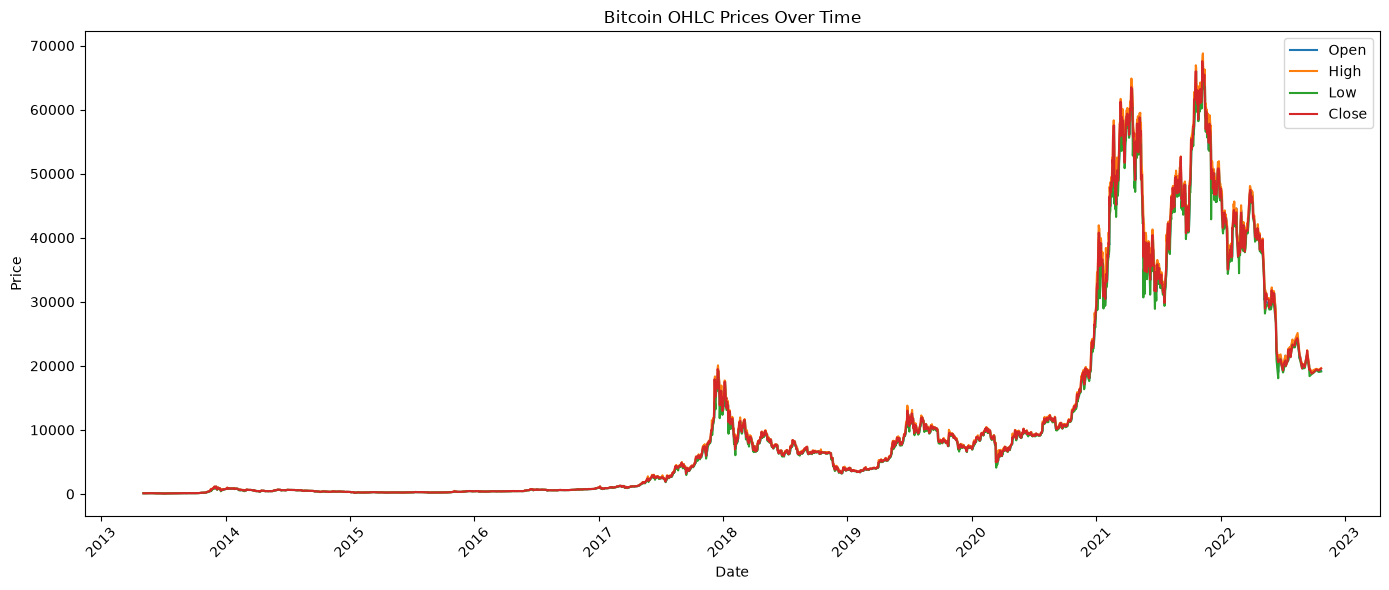

In [48]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Open"],
    label="Open"
)

plt.plot(
    df["Date"],
    df["High"],
    label="High"
)

plt.plot(
    df["Date"],
    df["Low"],
    label="Low"
)

plt.plot(
    df["Date"],
    df["Close"],
    label="Close"
)

plt.title(
    "Bitcoin OHLC Prices Over Time"
)

plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    GRAPH_PATH / "03_ohlc_prices.png",
    dpi=200
)

plt.show()

In [49]:
df["Daily_Return"] = (
    df["Close"].pct_change()
)

display(
    df[
        [
            "Date",
            "Close",
            "Daily_Return"
        ]
    ].head(10)
)

,Date,Close,Daily_Return
0,2013-05-05,115.910004,NaN
1,2013-05-06,112.300003,-0.031145
2,2013-05-07,111.500000,-0.007124
3,2013-05-08,113.566002,0.018529
4,2013-05-09,112.669998,-0.007890
5,2013-05-10,117.199997,0.040206
6,2013-05-11,115.242996,-0.016698
7,2013-05-12,115.000000,-0.002109
8,2013-05-13,117.980003,0.025913
9,2013-05-14,111.500000,-0.054925


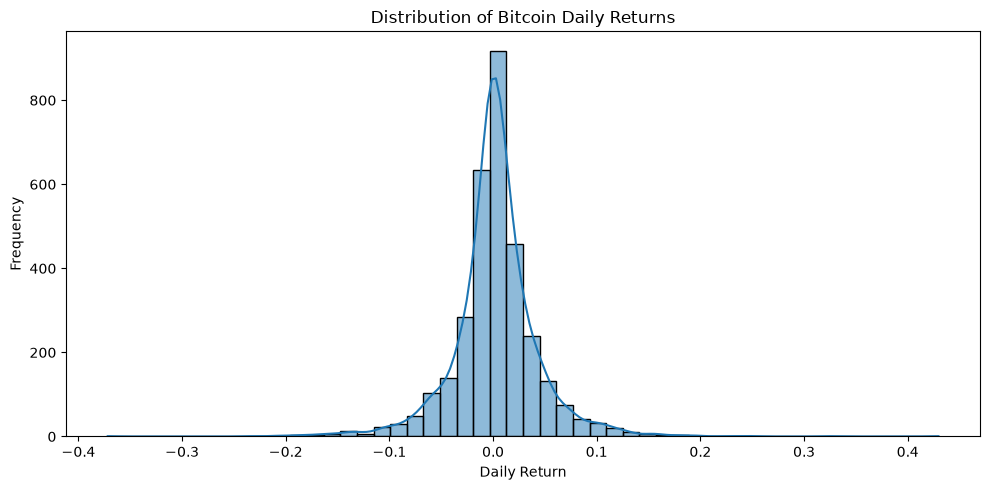

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Daily_Return"].dropna(),
    bins=50,
    kde=True
)

plt.title(
    "Distribution of Bitcoin Daily Returns"
)

plt.xlabel("Daily Return")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    GRAPH_PATH / "04_daily_returns_distribution.png",
    dpi=200
)

plt.show()

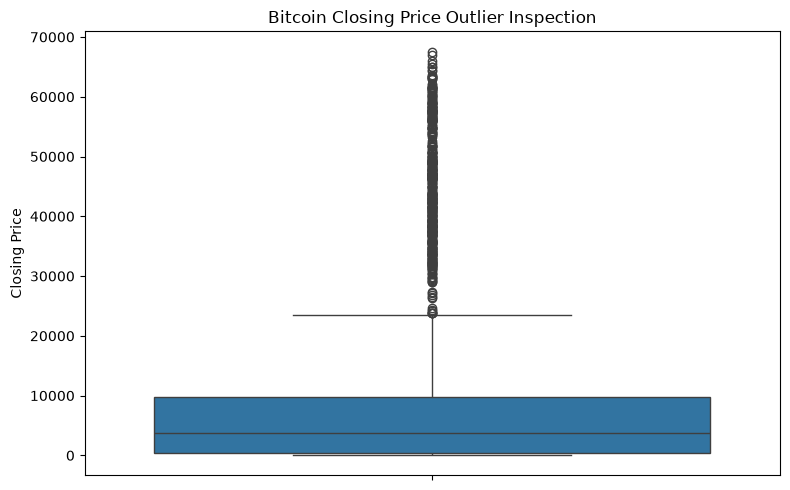

In [51]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    y=df["Close"]
)

plt.title(
    "Bitcoin Closing Price Outlier Inspection"
)

plt.ylabel("Closing Price")

plt.tight_layout()

plt.savefig(
    GRAPH_PATH / "05_close_price_outliers.png",
    dpi=200
)

plt.show()

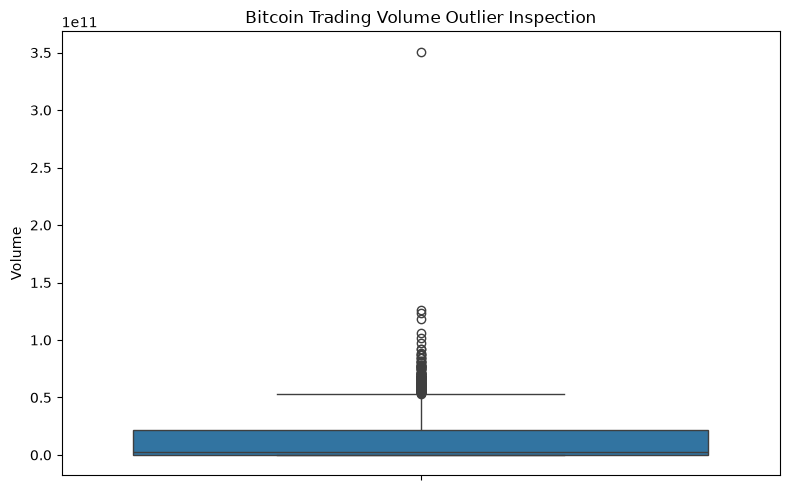

In [52]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    y=df["Volume"]
)

plt.title(
    "Bitcoin Trading Volume Outlier Inspection"
)

plt.ylabel("Volume")

plt.tight_layout()

plt.savefig(
    GRAPH_PATH / "06_volume_outliers.png",
    dpi=200
)

plt.show()

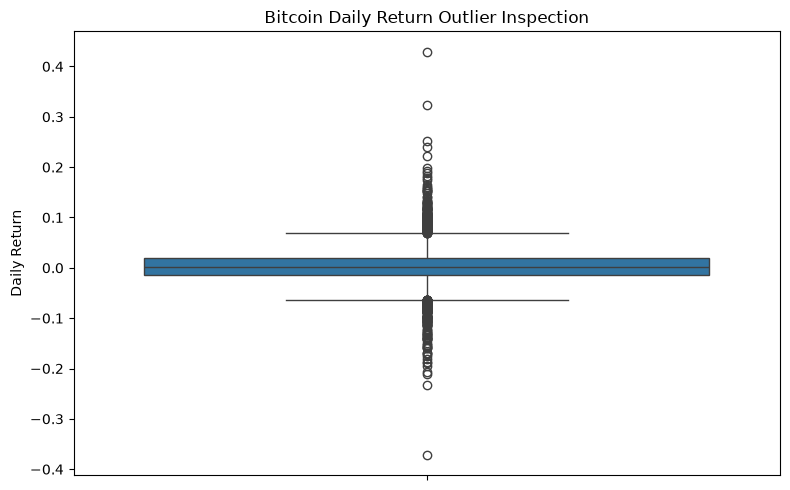

In [53]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    y=df["Daily_Return"].dropna()
)

plt.title(
    "Bitcoin Daily Return Outlier Inspection"
)

plt.ylabel("Daily Return")

plt.tight_layout()

plt.savefig(
    GRAPH_PATH / "07_return_outliers.png",
    dpi=200
)

plt.show()

In [54]:
correlation_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return"
]

correlation_matrix = df[
    correlation_columns
].corr()

display(
    correlation_matrix
)

,Open,High,Low,Close,Volume,Daily_Return
Open,1.000000,0.999550,0.999193,0.998932,0.745944,-0.023683
High,0.999550,1.000000,0.999110,0.999551,0.749534,-0.010829
Low,0.999193,0.999110,1.000000,0.999425,0.738957,-0.008939
Close,0.998932,0.999551,0.999425,1.000000,0.745176,0.001126
Volume,0.745944,0.749534,0.738957,0.745176,1.000000,-0.008389
Daily_Return,-0.023683,-0.010829,-0.008939,0.001126,-0.008389,1.000000


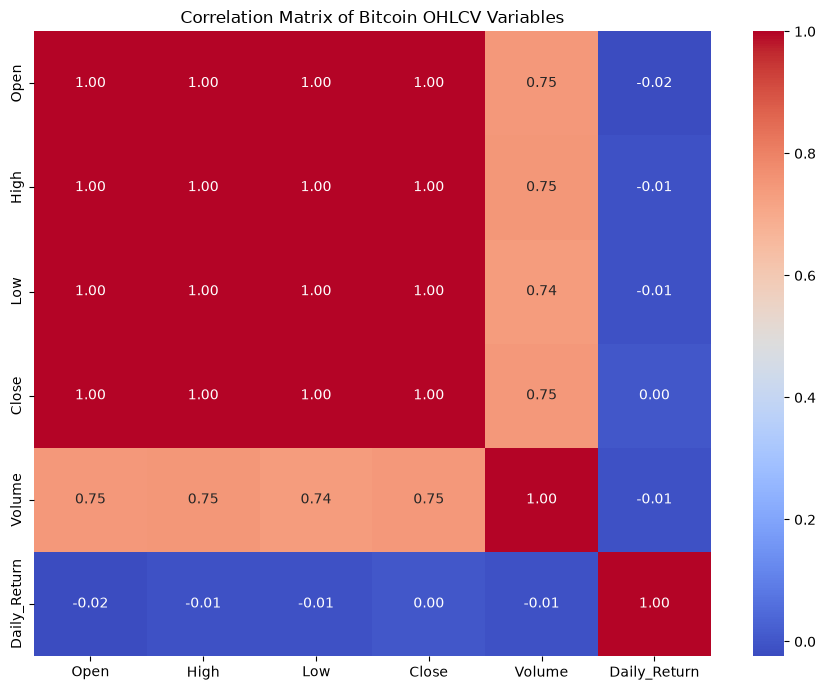

In [55]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title(
    "Correlation Matrix of Bitcoin OHLCV Variables"
)

plt.tight_layout()

plt.savefig(
    GRAPH_PATH / "08_correlation_heatmap.png",
    dpi=200
)

plt.show()

In [56]:
print("=" * 60)
print("FINAL BITCOIN DATA QUALITY CHECK")
print("=" * 60)

print("\nNumber of samples:")
print(len(df))

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values in OHLCV:")
print(
    df[
        ["Date", "Open", "High", "Low", "Close", "Volume"]
    ].isnull().sum().sum()
)

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate dates:")
print(df["Date"].duplicated().sum())

print("\nDates sorted:")
print(df["Date"].is_monotonic_increasing)

print("\nStart date:")
print(df["Date"].min())

print("\nEnd date:")
print(df["Date"].max())

FINAL BITCOIN DATA QUALITY CHECK

Number of samples:
3248

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return']

Missing values in OHLCV:
0

Duplicate rows:
0

Duplicate dates:
0

Dates sorted:
True

Start date:
2013-05-05 00:00:00

End date:
2022-10-23 00:00:00


In [57]:
from pathlib import Path

PROCESSED_PATH = Path("../data/processed")
PROCESSED_PATH.mkdir(
    parents=True,
    exist_ok=True
)

# Save ONLY the cleaned OHLCV data.
# Daily_Return will be recreated in Notebook 2.
clean_df = df[
    [
        "Date",
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ]
].copy()

output_file = (
    PROCESSED_PATH /
    "bitcoin_clean.csv"
)

clean_df.to_csv(
    output_file,
    index=False
)

print("Cleaned Bitcoin dataset saved successfully!")
print("Location:", output_file.resolve())
print("Shape:", clean_df.shape)

display(clean_df.head())

Cleaned Bitcoin dataset saved successfully!
Location: C:\Crypto_Forecasting_Project\LSTM_Light_BGM\data\processed\bitcoin_clean.csv
Shape: (3248, 6)


,Date,Open,High,Low,Close,Volume
0,2013-05-05,112.900002,118.800003,107.142998,115.910004,0.0
1,2013-05-06,115.980003,124.663002,106.639999,112.300003,0.0
2,2013-05-07,112.250000,113.444000,97.699997,111.500000,0.0
3,2013-05-08,109.599998,115.779999,109.599998,113.566002,0.0
4,2013-05-09,113.199997,113.459999,109.260002,112.669998,0.0
